In [1]:
import io
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.naive_bayes import MultinomialNB
from sklearn.pipeline import Pipeline
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

In [2]:
# 1. Upload do arquivo no Google Colab
from google.colab import files
uploaded = files.upload()
nome_arquivo = list(uploaded.keys())[0]
df = pd.read_csv(io.BytesIO(uploaded[nome_arquivo]))

Saving spam_ham_dataset.csv to spam_ham_dataset.csv


In [3]:
# 2. Tratamento de dados (remoção de duplicatas)
duplicados = df.duplicated(subset=['text']).sum()
print(f"Linhas duplicadas encontradas: {duplicados}")
df = df.drop_duplicates(subset=['text']).reset_index(drop=True)
print(f"Total de registros após limpeza: {len(df)}")

Linhas duplicadas encontradas: 178
Total de registros após limpeza: 4993


In [4]:
# 2. Separa os dados em 70% treino e 30% teste
X = df['text']
y = df['label_num']  # 0: normal, 1: spam
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.30, random_state=42, stratify=y
)

In [5]:
# 3. Cria e treina o modelo Naive Bayes com TF-IDF
modelo = Pipeline([
    ('tfidf', TfidfVectorizer(stop_words='english', lowercase=True)),
    ('nb', MultinomialNB())
])
modelo.fit(X_train, y_train)

Pipeline(steps=[('tfidf', TfidfVectorizer(stop_words='english')),
                ('nb', MultinomialNB())])


Acurácia: 92.52%

              precision    recall  f1-score   support

         Ham       0.91      1.00      0.95      1059
        Spam       0.99      0.75      0.86       439

    accuracy                           0.93      1498
   macro avg       0.95      0.88      0.90      1498
weighted avg       0.93      0.93      0.92      1498



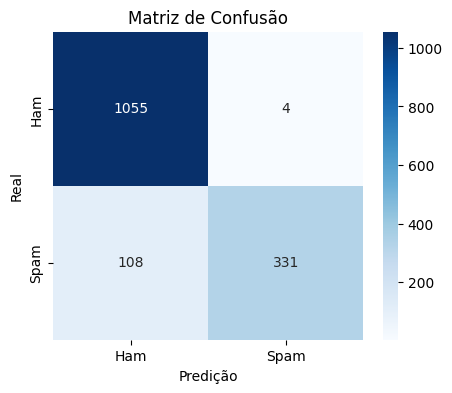

In [6]:
# 4. Avalia o desempenho no conjunto de teste
y_pred = modelo.predict(X_test)
print(f"\nAcurácia: {accuracy_score(y_test, y_pred) * 100:.2f}%\n")
print(classification_report(y_test, y_pred, target_names=['Ham', 'Spam']))
# Matriz de confusão
cm = confusion_matrix(y_test, y_pred)
plt.figure(figsize=(5, 4))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=['Ham', 'Spam'], yticklabels=['Ham', 'Spam'])
plt.xlabel('Predição')
plt.ylabel('Real')
plt.title('Matriz de Confusão')
plt.show()